# 04 – Who should we contact?

Not every user who leaves a cart is the same. Here the abandoners are compared with the buyers,
to find the group with the best chance to come back after a reminder.
Data: dbt table `otto.mart_sessions`.

In [1]:
import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine

sns.set_theme(style="white", font_scale=1.1)

DATA_DIR = Path("../data/processed")
FIG_DIR = Path("../docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# same colours as in notebook 03
COLORS = {
    "abandoner": "#e4572e",
    "quick_buyer": "#2a9d8f",
    "same_day_buyer": "#8ab17d",
    "slow_buyer": "#264653",
}
LABELS = {
    "abandoner": "Never ordered",
    "quick_buyer": "Within 1 hour",
    "same_day_buyer": "1–24 hours",
    "slow_buyer": "After 1+ day",
}
TYPE_ORDER = ["abandoner", "quick_buyer", "same_day_buyer", "slow_buyer"]

## Load the data

Downloaded once from PostgreSQL, then read from the local files.

In [ ]:
load_dotenv("../.env", override=True)
engine = create_engine(
    f"postgresql://{os.getenv('POSTGRES_USER')}:{os.getenv('POSTGRES_PASS')}"
    f"@{os.getenv('POSTGRES_HOST')}:{os.getenv('POSTGRES_PORT')}/{os.getenv('POSTGRES_DB')}"
)

def load_table(table_name, file_name):
    file_path = DATA_DIR / file_name
    if file_path.exists():
        return pd.read_parquet(file_path)
    table = pd.read_sql(f"SELECT * FROM otto.{table_name}", engine)
    table.to_parquet(file_path, index=False)
    return table

sessions = load_table("mart_sessions", "mart_sessions_all.parquet")
print(sessions.shape)

## 1. How do abandoners behave compared with buyers?

Only users with a cart (no `late_cart` or `other`). The table shows the median for each group.

In [3]:
cart_users = sessions[sessions["buyer_type"].isin(TYPE_ORDER)]

behaviour = cart_users.groupby("buyer_type").agg(
    users=("session_id", "count"),
    median_clicks=("n_clicks", "median"),
    median_products=("n_products", "median"),
    median_cart_adds=("n_carts", "median"),
    median_active_days=("active_days", "median"),
)
behaviour = behaviour.reindex(TYPE_ORDER)
behaviour

,users,median_clicks,median_products,median_cart_adds,median_active_days
buyer_type,,,,,
abandoner,159946,13.0,9.0,2.0,2.0
quick_buyer,81723,14.0,10.0,2.0,2.0
same_day_buyer,16263,35.0,23.0,6.0,3.0
slow_buyer,22992,55.0,36.0,7.0,8.0


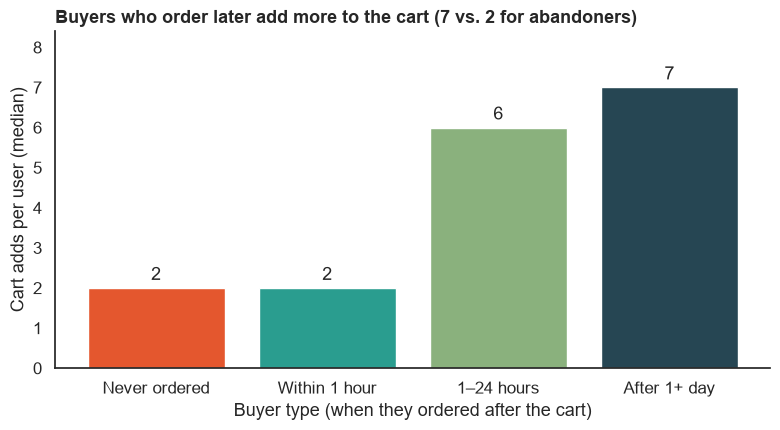

In [4]:
plot_data = behaviour.reset_index()
plot_data["label"] = plot_data["buyer_type"].map(LABELS)
abandoner_adds = behaviour.loc["abandoner", "median_cart_adds"]
slow_adds = behaviour.loc["slow_buyer", "median_cart_adds"]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(plot_data["label"], plot_data["median_cart_adds"], color=[COLORS[t] for t in plot_data["buyer_type"]])
ax.bar_label(bars, fmt="%.0f", padding=3)

ax.set_title(f"Buyers who order later add more to the cart ({slow_adds:.0f} vs. {abandoner_adds:.0f} for abandoners)",
             loc="left", fontweight="bold")
ax.set_ylabel("Cart adds per user (median)")
ax.set_xlabel("Buyer type (when they ordered after the cart)")
ax.set_ylim(0, plot_data["median_cart_adds"].max() * 1.2)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "05_cart_adds_by_type.png", dpi=200)
plt.show()

## 2. The target group

Abandoners who added several items to the cart. They showed more interest than a typical abandoner,
closer to the buyers who ordered later. This shows interest, not proof that a reminder works: that's what the A/B test is for.

In [5]:
MIN_CART_ADDS = 3  # more than the typical abandoner (median 2)

abandoners = cart_users[cart_users["buyer_type"] == "abandoner"]
target = abandoners[abandoners["n_carts"] >= MIN_CART_ADDS]
others = abandoners[abandoners["n_carts"] < MIN_CART_ADDS]
slow_buyers = cart_users[cart_users["buyer_type"] == "slow_buyer"]

print(f"Abandoners:                     {len(abandoners):,}")
print(f"{MIN_CART_ADDS}+ cart adds (target group):   {len(target):,} ({len(target) / len(abandoners):.0%})")
print(f"Fewer cart adds:                {len(others):,} ({len(others) / len(abandoners):.0%})")

Abandoners:                     159,946
3+ cart adds (target group):   56,620 (35%)
Fewer cart adds:                103,326 (65%)


In [6]:
columns = ["n_clicks", "n_products", "n_carts", "active_days"]

compare = pd.DataFrame({
    "Other abandoners": others[columns].median(),
    "Target abandoners": target[columns].median(),
    "Slow buyers": slow_buyers[columns].median(),
})
compare

,Other abandoners,Target abandoners,Slow buyers
n_clicks,8.0,26.0,55.0
n_products,6.0,19.0,36.0
n_carts,1.0,5.0,7.0
active_days,2.0,3.0,8.0


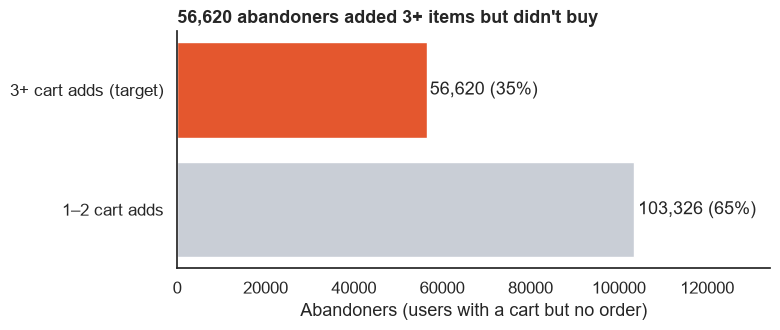

In [7]:
groups = pd.DataFrame({
    "group": [f"1–{MIN_CART_ADDS - 1} cart adds", f"{MIN_CART_ADDS}+ cart adds (target)"],
    "users": [len(others), len(target)],
})
groups["share"] = groups["users"] / groups["users"].sum() * 100

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(groups["group"], groups["users"], color=["#c9ced6", COLORS["abandoner"]])
for bar, users, share in zip(bars, groups["users"], groups["share"]):
    ax.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2, f"{users:,} ({share:.0f}%)", va="center")

ax.set_title(f"{len(target):,} abandoners added {MIN_CART_ADDS}+ items but didn't buy", loc="left", fontweight="bold")
ax.set_xlabel("Abandoners (users with a cart but no order)")
ax.set_xlim(0, groups["users"].max() * 1.3)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "06_target_group.png", dpi=200)
plt.show()